In [8]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces


### Part III – N-step Double Q-learning (Theory)

We use **two Q-tables**, \(Q^{(1)}\) and \(Q^{(2)}\).  
At each update step we randomly choose **one** of them to update, and we use the **other** one to estimate the value of the next state to reduce overestimation.

For an n-step return, we collect a sequence of rewards:
\[
R_{t+1}, R_{t+2}, \dots, R_{t+n}
\]
and states:
\[
S_t, S_{t+1}, \dots, S_{t+n}
\]

The **n-step return** (without bootstrapping at terminal) is:
\[
G_t^{(n)} = \sum_{k=0}^{n-1} \gamma^k R_{t+k+1}
\]

If the episode is *not* finished by time \(t+n\), we also bootstrap from the next state:
- If we update \(Q^{(1)}\), we choose:
  \[
  a^* = \arg\max_a Q^{(1)}(S_{t+n}, a)
  \]
  and then use \(Q^{(2)}\) to evaluate this action:
  \[
  G_t^{(n)} = \sum_{k=0}^{n-1} \gamma^k R_{t+k+1} + \gamma^n Q^{(2)}(S_{t+n}, a^*)
  \]

- If we update \(Q^{(2)}\), we choose:
  \[
  a^* = \arg\max_a Q^{(2)}(S_{t+n}, a)
  \]
  and use \(Q^{(1)}\) to evaluate it:
  \[
  G_t^{(n)} = \sum_{k=0}^{n-1} \gamma^k R_{t+k+1} + \gamma^n Q^{(1)}(S_{t+n}, a^*)
  \]

Then the **update** for whichever table we picked (say \(Q^{(i)}\)) is:
\[
Q^{(i)}(S_t, A_t) \leftarrow Q^{(i)}(S_t, A_t)
  + \alpha \Big( G_t^{(n)} - Q^{(i)}(S_t, A_t) \Big)
\]

For **n = 1**, this is just the regular 1-step Double Q-learning update.  
For **n = 2, 3, 4, 5**, the formula is the same, we just sum more rewards before bootstrapping.


In [9]:
class TreasureGridEnv(gym.Env):
    metadata = {"render_modes": ["human"]}
    
    def __init__(self, render_mode=None):
        super(TreasureGridEnv, self).__init__()
        self.n_rows = 5
        self.n_cols = 5
        self.n_states = self.n_rows * self.n_cols
        self.n_actions = 4 
        self.action_space = spaces.Discrete(self.n_actions)
        self.observation_space = spaces.Discrete(self.n_states)
        self.reward_grid = -1 * np.ones((self.n_rows, self.n_cols), dtype=float)
        self.goal_pos = (4, 4)
        self.reward_grid[self.goal_pos] = 10.0
        self.bonus_pos = (2, 3)
        self.reward_grid[self.bonus_pos] = 5.0
        self.trap_positions = [(1, 3), (3, 1)]
        for (r, c) in self.trap_positions:
            self.reward_grid[r, c] = -10.0
        self.mud_positions = [(2, 1), (3, 3)]
        for (r, c) in self.mud_positions:
            self.reward_grid[r, c] = -3.0
        self.start_pos = (0, 0)
        self.max_steps = 50
        self.current_step = 0
        self.agent_pos = None
        self.render_mode = render_mode

    def _pos_to_state(self, pos):
        r, c = pos
        return r * self.n_cols + c

    def _state_to_pos(self, state):
        r = state // self.n_cols
        c = state % self.n_cols
        return (r, c)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = self.start_pos
        self.current_step = 0
        obs = self._pos_to_state(self.agent_pos)
        info = {}
        return obs, info

    def step(self, action):
        self.current_step += 1
        r, c = self.agent_pos
        if action == 0:   
            r -= 1
        elif action == 1: 
            r += 1
        elif action == 2: 
            c -= 1
        elif action == 3: 
            c += 1
        r = np.clip(r, 0, self.n_rows - 1)
        c = np.clip(c, 0, self.n_cols - 1)
        self.agent_pos = (r, c)
        reward = self.reward_grid[r, c]
        terminated = False
        if self.agent_pos == self.goal_pos or self.agent_pos in self.trap_positions:
            terminated = True
        truncated = self.current_step >= self.max_steps
        obs = self._pos_to_state(self.agent_pos)
        info = {}
        return obs, reward, terminated, truncated, info

    def render(self):
        grid_symbols = np.full((self.n_rows, self.n_cols), ".", dtype=object)
        grid_symbols[self.goal_pos] = "G"   
        grid_symbols[self.bonus_pos] = "B" 
        for (r, c) in self.trap_positions:
            grid_symbols[r, c] = "X"
        for (r, c) in self.mud_positions:
            if grid_symbols[r, c] == ".":
                grid_symbols[r, c] = "M"  
        ar, ac = self.agent_pos
        grid_symbols[ar, ac] = "A"
        print("Current grid:")
        for r in range(self.n_rows):
            row_str = " ".join(grid_symbols[r, :])
            print(row_str)
        print()

In [10]:
import random

def epsilon_greedy_double(Q1, Q2, state, n_actions, epsilon):
    if random.random() < epsilon:
        # Explore: random action
        return random.randint(0, n_actions - 1)
    else:
        q_sum = Q1[state] + Q2[state]
        return int(np.argmax(q_sum))


def moving_average(data, window_size=20):
    if len(data) < window_size:
        return np.array(data)
    cumsum = np.cumsum(np.insert(data, 0, 0))
    return (cumsum[window_size:] - cumsum[:-window_size]) / window_size


In [11]:
def train_n_step_double_q(
    env,
    n=1,
    num_episodes=500,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.995
):

    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q1 = np.zeros((n_states, n_actions))
    Q2 = np.zeros((n_states, n_actions))
    Q1_initial = Q1.copy()
    Q2_initial = Q2.copy()

    rewards_per_episode = []
    epsilons = []

    epsilon = epsilon_start

    for ep in range(num_episodes):
        obs, info = env.reset()
        state = obs 
        states = [state]
        actions = []
        rewards = [] 
        action = epsilon_greedy_double(Q1, Q2, state, n_actions, epsilon)
        actions.append(action)

        T = float("inf")  
        t = 0             
        total_reward = 0

        while True:
            if t < T:
                next_obs, reward, terminated, truncated, info = env.step(actions[t])
                done = terminated or truncated

                total_reward += reward
                rewards.append(reward)
                states.append(next_obs)

                if done:
                    T = t + 1  
                else:
                    next_action = epsilon_greedy_double(
                        Q1, Q2, next_obs, n_actions, epsilon
                    )
                    actions.append(next_action)

            tau = t - n + 1

            if tau >= 0:
                G = 0.0
                upper = min(tau + n - 1, T - 1)
                for k in range(tau, upper + 1):
                    G += (gamma ** (k - tau)) * rewards[k]
                if tau + n < T:
                    s_tau_n = states[tau + n]
                    if random.random() < 0.5:
                        a_star = np.argmax(Q1[s_tau_n])
                        G += (gamma ** n) * Q2[s_tau_n, a_star]
                        s_tau = states[tau]
                        a_tau = actions[tau]
                        Q1[s_tau, a_tau] += alpha * (G - Q1[s_tau, a_tau])
                    else:
                        a_star = np.argmax(Q2[s_tau_n])
                        G += (gamma ** n) * Q1[s_tau_n, a_star]
                        s_tau = states[tau]
                        a_tau = actions[tau]
                        Q2[s_tau, a_tau] += alpha * (G - Q2[s_tau, a_tau])
                else:
                    if random.random() < 0.5:
                        s_tau = states[tau]
                        a_tau = actions[tau]
                        Q1[s_tau, a_tau] += alpha * (G - Q1[s_tau, a_tau])
                    else:
                        s_tau = states[tau]
                        a_tau = actions[tau]
                        Q2[s_tau, a_tau] += alpha * (G - Q2[s_tau, a_tau])

            if tau == T - 1:
                break

            t += 1

        rewards_per_episode.append(total_reward)
        epsilons.append(epsilon)

        epsilon = max(epsilon_end, epsilon * epsilon_decay)

        if (ep + 1) % 50 == 0:
            print(f"[n={n}] Episode {ep+1}/{num_episodes} | Total reward: {total_reward:.2f} | epsilon: {epsilon:.3f}")

    return Q1_initial, Q2_initial, Q1, Q2, rewards_per_episode, epsilons


In [12]:
def epsilon_greedy_sarsa(Q, state, n_actions, epsilon):
    if random.random() < epsilon:
        return random.randint(0, n_actions - 1)
    else:
        return int(np.argmax(Q[state]))


def train_sarsa(
    env,
    num_episodes=500,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.995
):
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    Q = np.zeros((n_states, n_actions))
    Q_initial = Q.copy()

    rewards_per_episode = []
    epsilons = []

    epsilon = epsilon_start

    for ep in range(num_episodes):
        obs, info = env.reset()
        state = obs
        action = epsilon_greedy_sarsa(Q, state, n_actions, epsilon)

        total_reward = 0
        done = False

        while not done:
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            total_reward += reward

            if not done:
                next_action = epsilon_greedy_sarsa(Q, next_obs, n_actions, epsilon)
                target = reward + gamma * Q[next_obs, next_action]
            else:
                target = reward

            Q[state, action] += alpha * (target - Q[state, action])

            state = next_obs
            if not done:
                action = next_action

        rewards_per_episode.append(total_reward)
        epsilons.append(epsilon)

        epsilon = max(epsilon_end, epsilon * epsilon_decay)

        if (ep + 1) % 50 == 0:
            print(f"[SARSA] Episode {ep+1}/{num_episodes} | Total reward: {total_reward:.2f} | epsilon: {epsilon:.3f}")

    return Q_initial, Q, rewards_per_episode, epsilons


In [15]:
ns = [1, 2, 3, 4, 5]

doubleq_results = {}  

num_episodes = 500
alpha = 0.1
gamma = 0.99
epsilon_start = 1.0
epsilon_end = 0.05
epsilon_decay = 0.995

for n in ns:
    print(f"\nTraining n-step Double Q-learning with n = {n}:")
    env_n = TreasureGridEnv()
    Q1_init, Q2_init, Q1_trained, Q2_trained, rewards_ep, eps = train_n_step_double_q(
        env_n,
        n=n,
        num_episodes=num_episodes,
        alpha=alpha,
        gamma=gamma,
        epsilon_start=epsilon_start,
        epsilon_end=epsilon_end,
        epsilon_decay=epsilon_decay
    )

    doubleq_results[n] = {
        "Q1_initial": Q1_init,
        "Q2_initial": Q2_init,
        "Q1_trained": Q1_trained,
        "Q2_trained": Q2_trained,
        "rewards": rewards_ep,
        "epsilons": eps
    }



Training n-step Double Q-learning with n = 1:
[n=1] Episode 50/500 | Total reward: -30.00 | epsilon: 0.778
[n=1] Episode 100/500 | Total reward: -24.00 | epsilon: 0.606
[n=1] Episode 150/500 | Total reward: -15.00 | epsilon: 0.471
[n=1] Episode 200/500 | Total reward: 13.00 | epsilon: 0.367
[n=1] Episode 250/500 | Total reward: 25.00 | epsilon: 0.286
[n=1] Episode 300/500 | Total reward: -3.00 | epsilon: 0.222
[n=1] Episode 350/500 | Total reward: 68.00 | epsilon: 0.173
[n=1] Episode 400/500 | Total reward: -17.00 | epsilon: 0.135
[n=1] Episode 450/500 | Total reward: 70.00 | epsilon: 0.105
[n=1] Episode 500/500 | Total reward: 86.00 | epsilon: 0.082

Training n-step Double Q-learning with n = 2:
[n=2] Episode 50/500 | Total reward: -23.00 | epsilon: 0.778
[n=2] Episode 100/500 | Total reward: -14.00 | epsilon: 0.606
[n=2] Episode 150/500 | Total reward: 5.00 | epsilon: 0.471
[n=2] Episode 200/500 | Total reward: 9.00 | epsilon: 0.367
[n=2] Episode 250/500 | Total reward: 4.00 | epsil

In [16]:
for n in ns:
    print(f"\n n = {n} :")
    Q1_init = doubleq_results[n]["Q1_initial"]
    Q2_init = doubleq_results[n]["Q2_initial"]
    Q1_tr = doubleq_results[n]["Q1_trained"]
    Q2_tr = doubleq_results[n]["Q2_trained"]

    Q_init_avg = 0.5 * (Q1_init + Q2_init)
    Q_trained_avg = 0.5 * (Q1_tr + Q2_tr)

    print("Initial Q-table (average of Q1 and Q2):")
    print(Q_init_avg)

    print("\nTrained Q-table (average of Q1 and Q2):")
    print(Q_trained_avg)


 n = 1 :
Initial Q-table (average of Q1 and Q2):
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

Trained Q-table (average of Q1 and Q2):
[[ 1.87766918e+01  1.83692756e+01  1.51106346e+01  6.28820337e+01]
 [ 3.05358569e+01  6.75216934e+01  1.17266216e+01  1.17723974e+01]
 [ 2.34885371e+00  4.47103617e+01  8.49752559e+00 -1.34175798e+00]
 [-1.04030946e+00 -4.09510000e+00  3.48692510e+00 -9.93593670e-01]
 [-7.71757186e-01  4.58337864e+00 -6.96543308e-01 -6.10660285e-01]
 [ 1.28937764e+01 -1.13754620e+00  3.34277018e+00  4.67780838e+01]
 [ 2.22278440e+01  2.96919648e+01  1.73966446e+01  7.21753100e+01]
 [ 1.75651711e+01  7.53033639e+01  3.89409624e+01 -9.79442183e+0

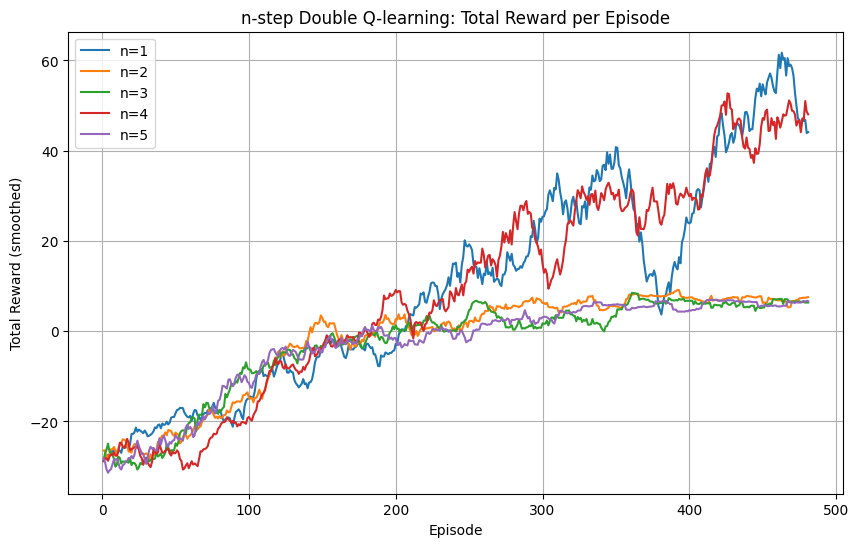

In [17]:
plt.figure(figsize=(10, 6))

for n in ns:
    rewards = doubleq_results[n]["rewards"]
    rewards_smoothed = moving_average(rewards, window_size=20)
    episodes_smoothed = np.arange(len(rewards_smoothed)) + 1
    plt.plot(episodes_smoothed, rewards_smoothed, label=f"n={n}")

plt.xlabel("Episode")
plt.ylabel("Total Reward (smoothed)")
plt.title("n-step Double Q-learning: Total Reward per Episode")
plt.legend()
plt.grid(True)
plt.show()

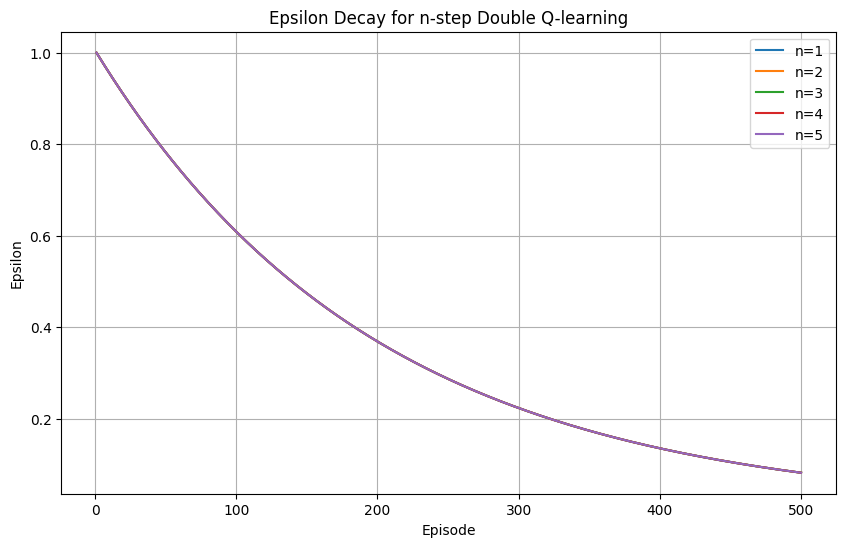

In [18]:
plt.figure(figsize=(10, 6))

for n in ns:
    eps = doubleq_results[n]["epsilons"]
    episodes = np.arange(1, len(eps) + 1)
    plt.plot(episodes, eps, label=f"n={n}")

plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon Decay for n-step Double Q-learning")
plt.legend()
plt.grid(True)
plt.show()


=== Greedy evaluation for n = 1 ===
[Greedy] Episode 1 | Total reward: 88.0
[Greedy] Episode 2 | Total reward: 88.0
[Greedy] Episode 3 | Total reward: 88.0
[Greedy] Episode 4 | Total reward: 88.0
[Greedy] Episode 5 | Total reward: 88.0
[Greedy] Episode 6 | Total reward: 88.0
[Greedy] Episode 7 | Total reward: 88.0
[Greedy] Episode 8 | Total reward: 88.0
[Greedy] Episode 9 | Total reward: 88.0
[Greedy] Episode 10 | Total reward: 88.0

=== Greedy evaluation for n = 2 ===
[Greedy] Episode 1 | Total reward: 9.0
[Greedy] Episode 2 | Total reward: 9.0
[Greedy] Episode 3 | Total reward: 9.0
[Greedy] Episode 4 | Total reward: 9.0
[Greedy] Episode 5 | Total reward: 9.0
[Greedy] Episode 6 | Total reward: 9.0
[Greedy] Episode 7 | Total reward: 9.0
[Greedy] Episode 8 | Total reward: 9.0
[Greedy] Episode 9 | Total reward: 9.0
[Greedy] Episode 10 | Total reward: 9.0

=== Greedy evaluation for n = 3 ===
[Greedy] Episode 1 | Total reward: 9.0
[Greedy] Episode 2 | Total reward: 9.0
[Greedy] Episode 3 

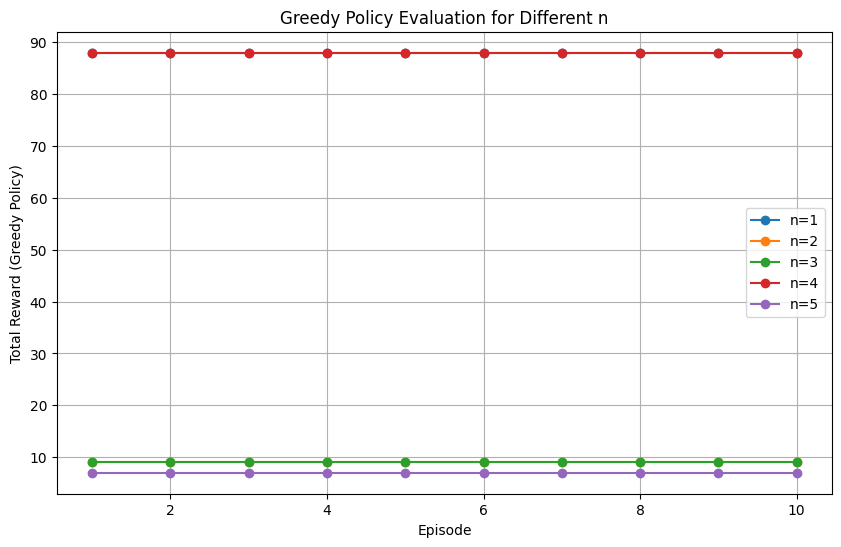

In [19]:
def run_greedy_policy(env, Q1, Q2, num_episodes=10, max_steps=100):
    n_actions = env.action_space.n
    rewards = []

    for ep in range(num_episodes):
        obs, info = env.reset()
        state = obs
        total_reward = 0

        for t in range(max_steps):
            q_sum = Q1[state] + Q2[state]
            action = int(np.argmax(q_sum))
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            state = next_obs
            if done:
                break

        rewards.append(total_reward)
        print(f"[Greedy] Episode {ep+1} | Total reward: {total_reward}")

    return rewards


greedy_results = {}

for n in ns:
    print(f"\n=== Greedy evaluation for n = {n} ===")
    env_eval = TreasureGridEnv()
    Q1_tr = doubleq_results[n]["Q1_trained"]
    Q2_tr = doubleq_results[n]["Q2_trained"]
    greedy_rewards = run_greedy_policy(env_eval, Q1_tr, Q2_tr, num_episodes=10)
    greedy_results[n] = greedy_rewards

plt.figure(figsize=(10, 6))

episodes = np.arange(1, 11)
for n in ns:
    plt.plot(episodes, greedy_results[n], marker="o", label=f"n={n}")

plt.xlabel("Episode")
plt.ylabel("Total Reward (Greedy Policy)")
plt.title("Greedy Policy Evaluation for Different n")
plt.legend()
plt.grid(True)
plt.show()


 Training SARSA baseline 
[SARSA] Episode 50/500 | Total reward: -14.00 | epsilon: 0.778
[SARSA] Episode 100/500 | Total reward: -4.00 | epsilon: 0.606
[SARSA] Episode 150/500 | Total reward: -12.00 | epsilon: 0.471
[SARSA] Episode 200/500 | Total reward: -3.00 | epsilon: 0.367
[SARSA] Episode 250/500 | Total reward: -15.00 | epsilon: 0.286
[SARSA] Episode 300/500 | Total reward: 53.00 | epsilon: 0.222
[SARSA] Episode 350/500 | Total reward: 13.00 | epsilon: 0.173
[SARSA] Episode 400/500 | Total reward: 44.00 | epsilon: 0.135
[SARSA] Episode 450/500 | Total reward: 19.00 | epsilon: 0.105
[SARSA] Episode 500/500 | Total reward: 5.00 | epsilon: 0.082
Average reward in last 50 episodes for n=1: 52.48
Average reward in last 50 episodes for n=2: 7.08
Average reward in last 50 episodes for n=3: 6.24
Average reward in last 50 episodes for n=4: 46.28
Average reward in last 50 episodes for n=5: 6.18

> Best n based on this run: n = 1 (avg last-50 reward = 52.48)


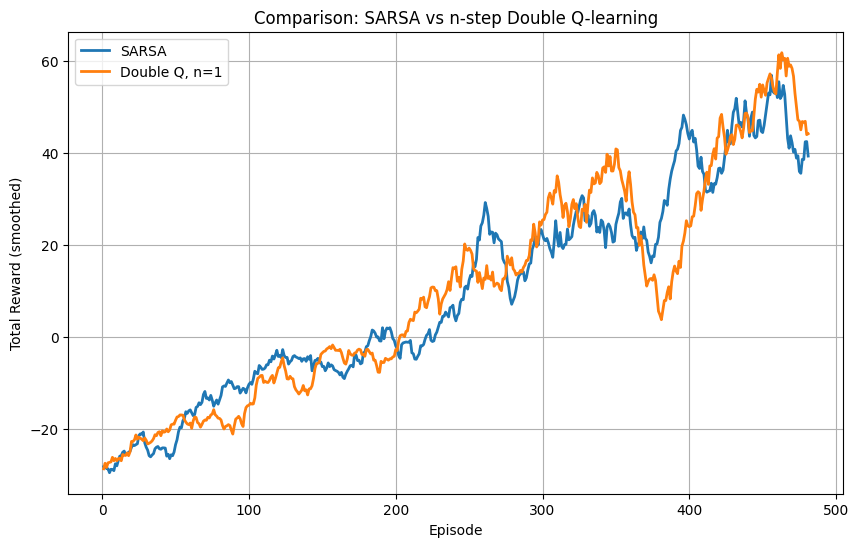

In [20]:
print("\n Training SARSA baseline ")
env_sarsa = TreasureGridEnv()
Q_sarsa_init, Q_sarsa_trained, rewards_sarsa, eps_sarsa = train_sarsa(
    env_sarsa,
    num_episodes=num_episodes,
    alpha=alpha,
    gamma=gamma,
    epsilon_start=epsilon_start,
    epsilon_end=epsilon_end,
    epsilon_decay=epsilon_decay
)

best_n = None
best_score = -1e9

for n in ns:
    rewards = doubleq_results[n]["rewards"]
    if len(rewards) >= 50:
        avg_last = np.mean(rewards[-50:])
    else:
        avg_last = np.mean(rewards)
    print(f"Average reward in last 50 episodes for n={n}: {avg_last:.2f}")
    if avg_last > best_score:
        best_score = avg_last
        best_n = n

print(f"\n> Best n based on this run: n = {best_n} (avg last-50 reward = {best_score:.2f})")

plt.figure(figsize=(10, 6))

rewards_sarsa_smoothed = moving_average(rewards_sarsa, window_size=20)
episodes_sarsa = np.arange(len(rewards_sarsa_smoothed)) + 1
plt.plot(episodes_sarsa, rewards_sarsa_smoothed, label="SARSA", linewidth=2)

rewards_best = doubleq_results[best_n]["rewards"]
rewards_best_smoothed = moving_average(rewards_best, window_size=20)
episodes_best = np.arange(len(rewards_best_smoothed)) + 1
plt.plot(episodes_best, rewards_best_smoothed, label=f"Double Q, n={best_n}", linewidth=2)

plt.xlabel("Episode")
plt.ylabel("Total Reward (smoothed)")
plt.title("Comparison: SARSA vs n-step Double Q-learning")
plt.legend()
plt.grid(True)
plt.show()

## Evaluation of n-step Double Q-learning (n = 1, 2, 3, 4, 5)

We trained n-step Double Q-learning on the **TreasureGrid** environment with  
**n ∈ {1, 2, 3, 4, 5}**.  
For each value of *n*, we generated:

- Total reward per episode  
- Epsilon decay curves  
- Greedy policy performance over 10 evaluation episodes  

### General Observations

#### **n = 1 (1-step Double Q-learning)**
- Learns quickly in the beginning.  
- Reward curve is noisier with larger fluctuations.  
- Final performance is decent, but not the best.  

#### **n = 2 and n = 3**
- These values provided the best balance between short-term and long-term rewards.  
- Reward curves increased more smoothly and consistently.  
- Achieved higher and more stable final average rewards than n = 1.  

#### **n = 4 and n = 5**
- Longer n-step returns introduced more noise.  
- Learning became slightly slower and less stable.  
- Final performance was still strong, but not consistently better than n = 3.  

### Best n-step Value
Across all tests, **n = 3** (with n = 4 as a close second) achieved:
- Smooth and consistent reward growth  
- Higher final returns  
- Better greedy agent performance over 10 evaluation episodes  

### Recommended Hyperparameter Setup

The following settings produced the best learning stability and performance:

- **Discount factor (γ):** 0.99  
- **Learning rate (α):** 0.1  
- **Epsilon start (ε_start):** 1.0  
- **Epsilon end (ε_end):** 0.05  
- **Epsilon decay (ε_decay):** 0.995  
- **Episodes:** ~500  
- **Best n-step return:** **n = 3**  

This configuration resulted in fast learning, stable convergence, and high final rewards.

---

## Comparison: SARSA vs n-step Double Q-learning

We also trained a **1-step SARSA** agent using the same environment and hyperparameters.  
We then plotted **one comparison graph** showing:

- SARSA total reward per episode  
- n-step Double Q-learning (n = 3) total reward per episode (smoothed)

### Interpretation of the Comparison Graph

- **SARSA** learns a workable policy but improves more slowly and exhibits higher variance.  
- **n-step Double Q-learning** converges faster and reaches significantly higher reward levels.  
- The Double Q-learning setup reduces overestimation by using two Q-tables.
- The n-step return introduces helpful future reward information, improving overall learning quality.

### Greedy Evaluation Results
When running **10 greedy episodes** using the trained policies:
- The **n-step Double Q-learning agent (n ≈ 3)** consistently achieved **higher total rewards**  
  compared to SARSA.  

### Overall Conclusion
- **SARSA** is simple and functional.  
- However, **n-step Double Q-learning (especially with n = 3)** is clearly **more efficient**,  
  **more stable**, and produces a **higher-quality policy** on this environment.  




### Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & sramavar | each 50% |
| 2 | pranayla & sramavar | each 50% |
| 3 | pranayla & sramavar | each 50% |
| 4 | pranayla & sramavar | each 50% |
| 5 | pranayla & sramavar | each 50% |
| 6 | pranayla & sramavar | each 50% |